In [1]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt 
import numpy as np 

In [2]:

df = pd.read_csv("US_Accidents_March23_sampled_500k.csv")
df.describe()

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,500000.000000,500000.000000,500000.000000,279623.000000,279623.000000,500000.000000,489534.000000,370983.000000,488870.000000,491072.000000,488709.000000,463013.000000,357384.000000
mean,2.212748,36.206421,-94.736583,36.273192,-95.776553,0.564317,61.646254,58.229028,64.834921,29.536621,9.091540,7.681347,0.008289
std,0.486661,5.071411,17.405761,5.265333,18.120211,1.774872,19.000133,22.352246,22.826158,1.008666,2.708083,5.431361,0.101865
min,1.000000,24.562117,-124.497420,24.570110,-124.497419,0.000000,-77.800000,-53.200000,1.000000,0.120000,0.000000,0.000000,0.000000
25%,2.000000,33.416823,-117.233047,33.474773,-117.778324,0.000000,49.000000,43.000000,48.000000,29.370000,10.000000,4.600000,0.000000
50%,2.000000,35.832147,-87.794365,36.192669,-88.039013,0.029000,64.000000,62.000000,67.000000,29.860000,10.000000,7.000000,0.000000
75%,2.000000,40.082443,-80.359601,40.181341,-80.252449,0.465000,76.000000,75.000000,84.000000,30.030000,10.000000,10.400000,0.000000
max,4.000000,48.999569,-67.484130,48.998901,-67.484130,193.479996,207.000000,207.000000,100.000000,38.440000,130.000000,822.800000,10.130000


In [3]:
# const value 
FILL_NA_VALUE = "NA"
ZERO = 0
# dropping and filling NA
dfClean = df.drop(["ID", "End_Lat", "End_Lng", "Wind_Chill(F)", "Airport_Code"], axis=1)
# fill string null will "NA"
dfClean["Description"] = dfClean["Description"].fillna(FILL_NA_VALUE)
dfClean["Street"] = dfClean["Street"].fillna(FILL_NA_VALUE)
dfClean["City"] = dfClean["City"].fillna(FILL_NA_VALUE)
dfClean["Zipcode"] = dfClean["Zipcode"].fillna(FILL_NA_VALUE)
dfClean["Timezone"] = dfClean["Timezone"].fillna(FILL_NA_VALUE)
dfClean["Weather_Timestamp"] = dfClean["Weather_Timestamp"].fillna(FILL_NA_VALUE)
dfClean["Wind_Direction"] = dfClean["Wind_Direction"].fillna(FILL_NA_VALUE)
dfClean["Weather_Condition"] = dfClean["Weather_Condition"].fillna(FILL_NA_VALUE)
dfClean["Sunrise_Sunset"] = dfClean["Sunrise_Sunset"].fillna(FILL_NA_VALUE)
dfClean["Civil_Twilight"] = dfClean["Civil_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Nautical_Twilight"] = dfClean["Nautical_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Astronomical_Twilight"] = dfClean["Astronomical_Twilight"].fillna(FILL_NA_VALUE)

# fill float NA with mean
dfClean["Temperature(F)"] = dfClean["Temperature(F)"].fillna(dfClean["Temperature(F)"].mean())
dfClean["Humidity(%)"] = dfClean["Humidity(%)"].fillna(dfClean["Humidity(%)"].mean())
dfClean["Pressure(in)"] = dfClean["Pressure(in)"].fillna(dfClean["Pressure(in)"].mean())
dfClean["Visibility(mi)"] = dfClean["Visibility(mi)"].fillna(dfClean["Visibility(mi)"].mean())
dfClean["Wind_Speed(mph)"] = dfClean["Wind_Speed(mph)"].fillna(dfClean["Wind_Speed(mph)"].mean())
dfClean["Precipitation(in)"] = dfClean["Precipitation(in)"].fillna(ZERO)

dfClean.info()


<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 500000 non-null  str    
 1   Severity               500000 non-null  int64  
 2   Start_Time             500000 non-null  str    
 3   End_Time               500000 non-null  str    
 4   Start_Lat              500000 non-null  float64
 5   Start_Lng              500000 non-null  float64
 6   Distance(mi)           500000 non-null  float64
 7   Description            500000 non-null  str    
 8   Street                 500000 non-null  str    
 9   City                   500000 non-null  str    
 10  County                 500000 non-null  str    
 11  State                  500000 non-null  str    
 12  Zipcode                500000 non-null  str    
 13  Country                500000 non-null  str    
 14  Timezone               500000 non-null  str    

In [4]:
dfClean.corr(numeric_only=True)

,Severity,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
Severity,1.000000,0.069241,0.053602,0.032403,-0.018421,0.019109,0.042442,0.000024,0.039279,0.010019,...,-0.003866,0.051173,-0.008565,-0.010483,-0.002229,-0.045979,-0.047772,-0.004463,-0.105085,NaN
Start_Lat,0.069241,1.000000,-0.067316,0.064981,-0.440745,0.020518,-0.192187,-0.085786,0.032598,0.000097,...,0.003880,0.046042,-0.005522,0.005292,-0.002610,-0.048778,-0.004452,-0.004165,-0.062910,NaN
Start_Lng,0.053602,-0.067316,1.000000,0.005918,-0.009126,0.174697,0.191625,-0.012634,0.075870,0.026791,...,0.026646,-0.031554,0.007920,-0.015819,0.000523,0.006040,-0.031623,-0.001639,0.071668,NaN
Distance(mi),0.032403,0.064981,0.005918,1.000000,-0.056247,0.009493,-0.097268,-0.038624,0.008389,0.002639,...,-0.008140,0.030543,-0.009665,-0.017455,-0.001273,-0.039912,-0.030749,-0.005792,-0.108498,NaN
Temperature(F),-0.018421,-0.440745,-0.009126,-0.056247,1.000000,-0.330416,0.107917,0.211601,0.031888,-0.004736,...,0.001925,-0.019660,0.007663,0.003489,0.002172,0.033097,0.008767,0.004139,0.047263,NaN
Humidity(%),0.019109,0.020518,0.174697,0.009493,-0.330416,1.000000,0.118163,-0.377311,-0.165359,0.073634,...,0.000058,-0.001732,-0.008093,-0.001174,-0.000189,-0.007503,-0.016249,-0.001953,-0.015711,NaN
Pressure(in),0.042442,-0.192187,0.191625,-0.097268,0.107917,0.118163,1.000000,0.035090,-0.023375,0.002626,...,0.006325,0.031455,-0.002314,0.016423,0.001803,0.036204,-0.006014,0.000889,0.039585,NaN
Visibility(mi),0.000024,-0.085786,-0.012634,-0.038624,0.211601,-0.377311,0.035090,1.000000,0.014626,-0.104529,...,0.003639,-0.005409,0.008121,0.003151,0.000045,0.016183,0.005028,0.001139,0.031371,NaN
Wind_Speed(mph),0.039279,0.032598,0.075870,0.008389,0.031888,-0.165359,-0.023375,0.014626,1.000000,0.019385,...,0.000815,0.008485,0.001853,-0.001285,-0.001490,0.016177,-0.002748,0.000515,0.020384,NaN
Precipitation(in),0.010019,0.000097,0.026791,0.002639,-0.004736,0.073634,0.002626,-0.104529,0.019385,1.000000,...,-0.001494,0.002138,-0.001432,0.000480,-0.000032,-0.002842,0.001813,0.000250,0.002274,NaN


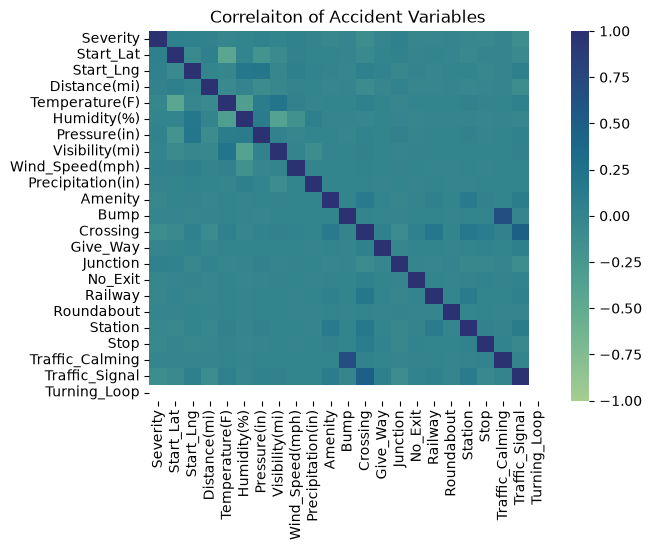

In [5]:
sns.heatmap(dfClean.corr(numeric_only=True), cmap='crest', vmin=-1, vmax=1);
plt.title('Correlaiton of Accident Variables')
plt.show()

In [6]:
weather = dfClean[['Severity','Distance(mi)','Temperature(F)','Humidity(%)','Pressure(in)','Visibility(mi)','Wind_Speed(mph)']].copy()
weather.head()


,Severity,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph)
0,2,0.000,77.0,62.0,29.92,10.0,5.0
1,2,0.056,45.0,48.0,29.91,10.0,5.0
2,2,0.022,68.0,73.0,29.79,10.0,13.0
3,2,1.054,27.0,86.0,28.49,10.0,15.0
4,2,0.046,42.0,34.0,29.77,10.0,0.0


In [7]:
weather.corr()

,Severity,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph)
Severity,1.000000,0.032403,-0.018421,0.019109,0.042442,0.000024,0.039279
Distance(mi),0.032403,1.000000,-0.056247,0.009493,-0.097268,-0.038624,0.008389
Temperature(F),-0.018421,-0.056247,1.000000,-0.330416,0.107917,0.211601,0.031888
Humidity(%),0.019109,0.009493,-0.330416,1.000000,0.118163,-0.377311,-0.165359
Pressure(in),0.042442,-0.097268,0.107917,0.118163,1.000000,0.035090,-0.023375
Visibility(mi),0.000024,-0.038624,0.211601,-0.377311,0.035090,1.000000,0.014626
Wind_Speed(mph),0.039279,0.008389,0.031888,-0.165359,-0.023375,0.014626,1.000000


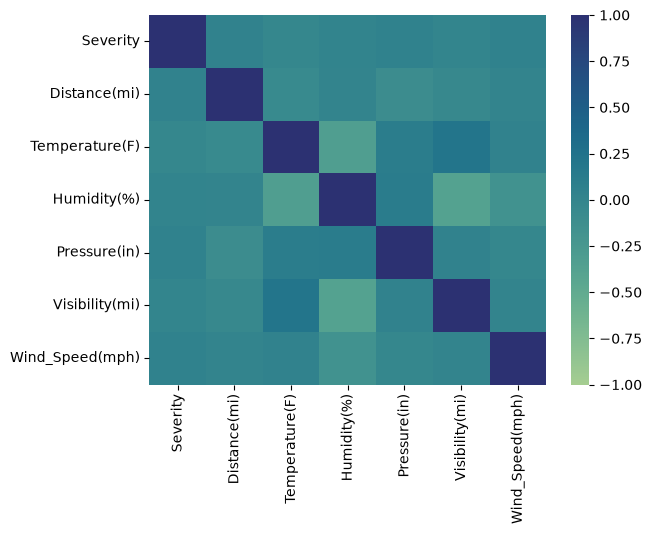

In [8]:
sns.heatmap(weather.corr(), cmap='crest', vmin=-1, vmax=1);

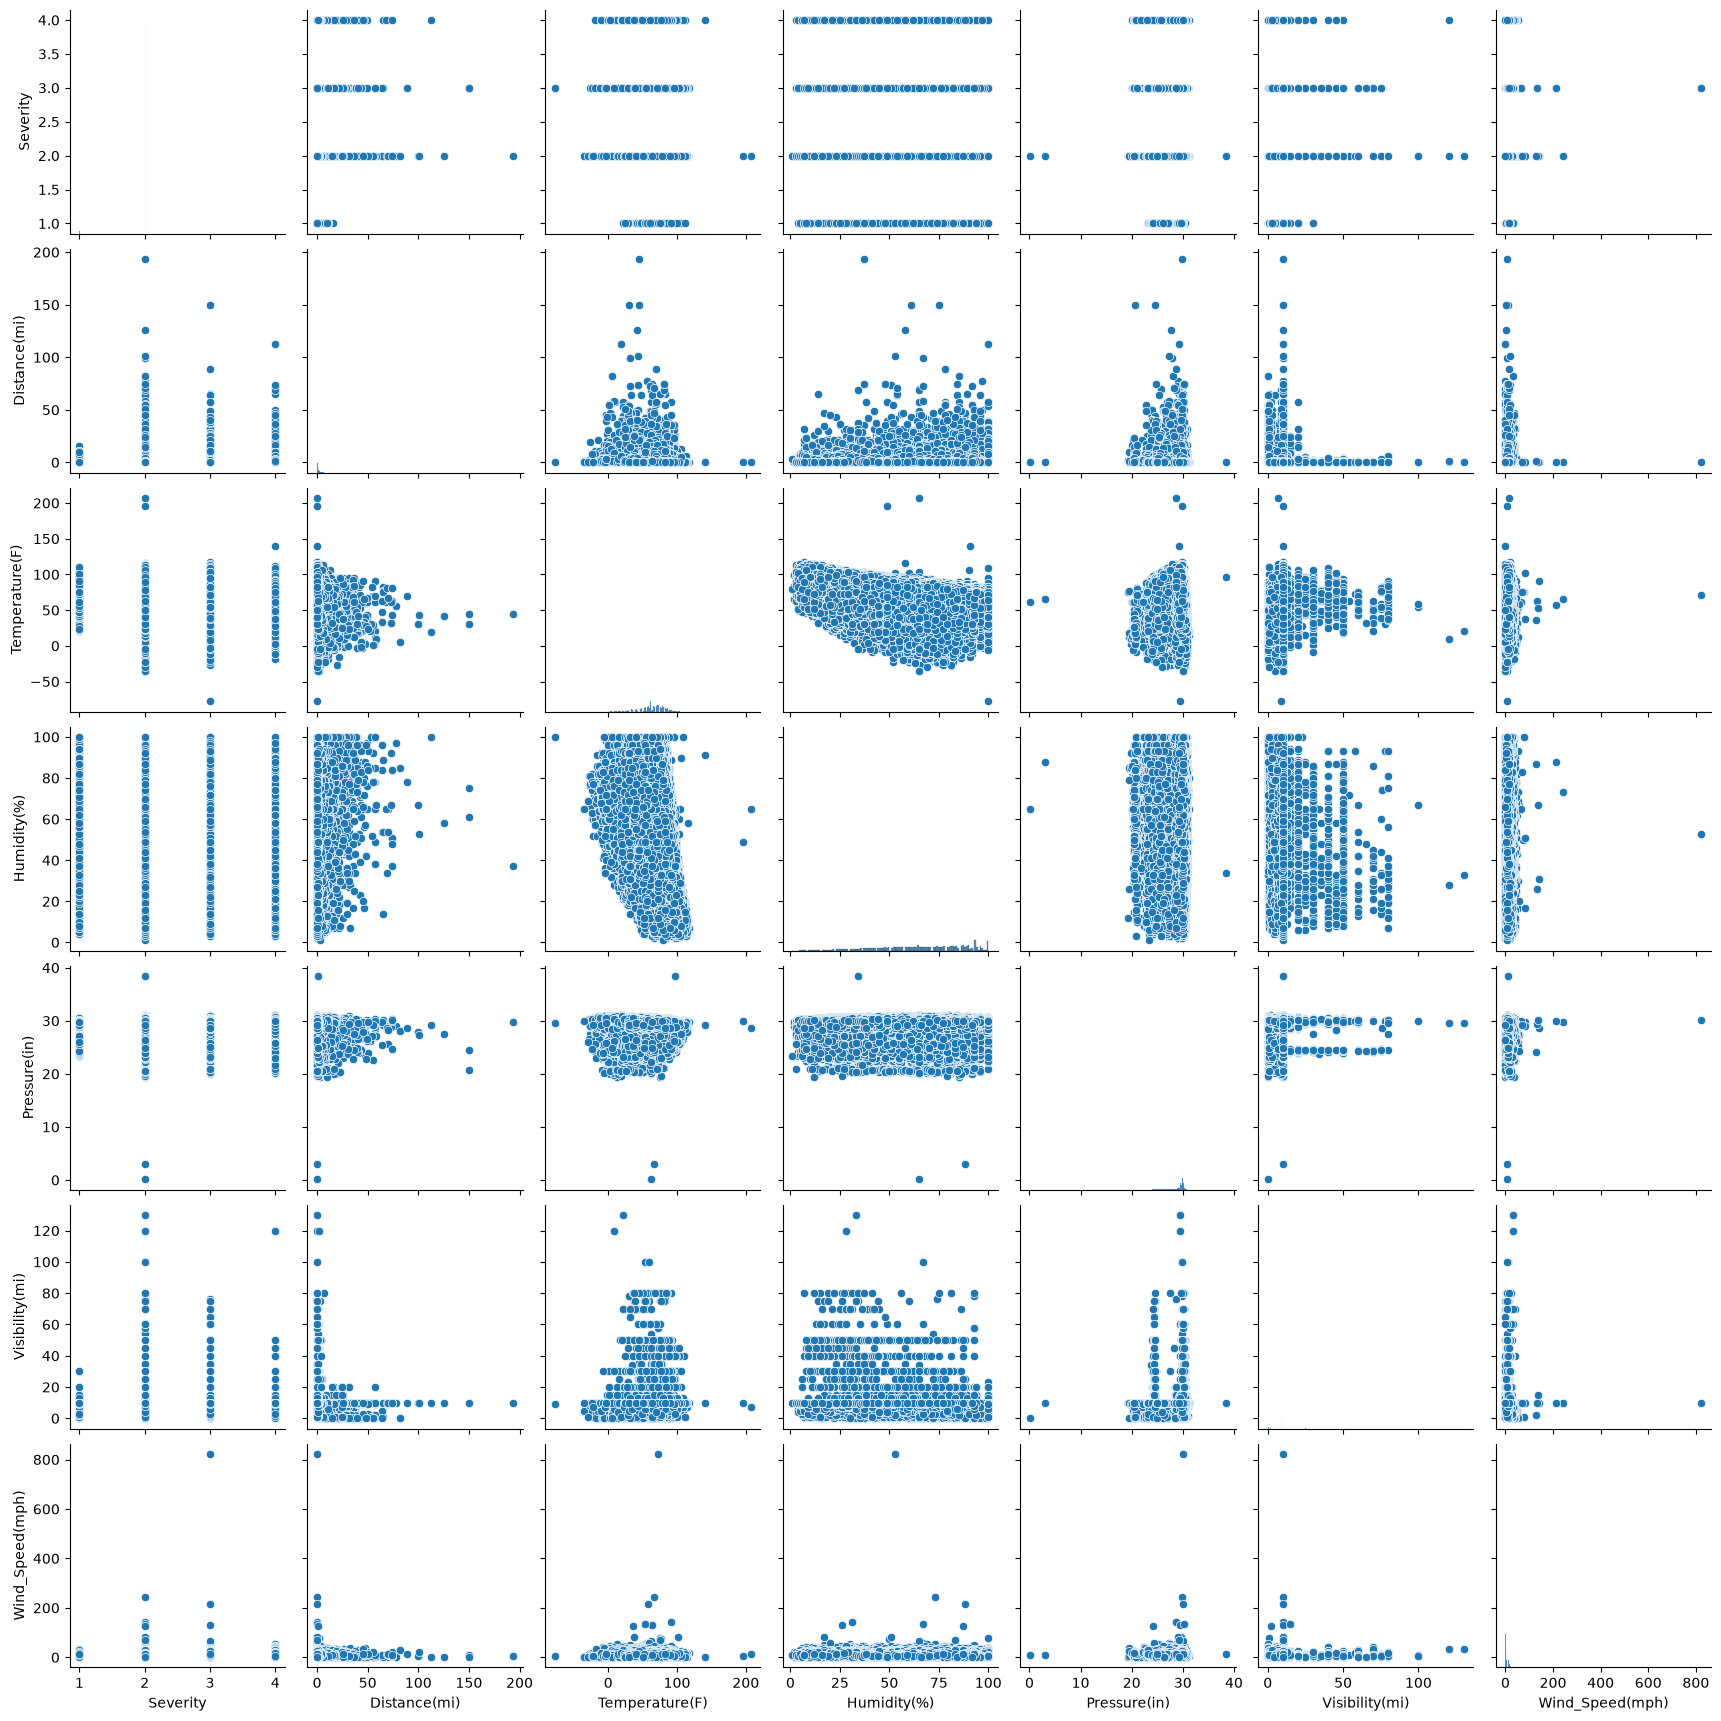

In [9]:
sns.pairplot(data=weather);

In [10]:
# Noticed outliers found within wind_speed(mph)
print(weather['Wind_Speed(mph)'].describe())

print(
    weather['Wind_Speed(mph)']
    .sort_values(ascending=False)
    .head(50)
)

count    500000.000000
mean          7.681347
std           5.226612
min           0.000000
25%           5.000000
50%           7.681347
75%          10.000000
max         822.800000
Name: Wind_Speed(mph), dtype: float64
371110    822.8
111820    243.0
463693    214.0
9155      142.0
269849    135.8
105752    131.0
324284    127.0
399664     82.0
466774     81.0
253113     77.0
308684     75.0
483870     70.0
403412     66.7
446108     59.0
8542       58.0
33459      52.0
398650     52.0
168904     52.0
277496     51.0
392897     51.0
42370      51.0
378877     49.5
175751     47.2
359487     47.0
160445     47.0
2070       47.0
10613      46.0
179649     46.0
29408      46.0
206781     46.0
330592     46.0
231057     45.0
289458     45.0
377721     45.0
470305     45.0
280771     45.0
368510     44.0
230111     44.0
400113     43.0
341043     43.0
228326     43.0
320596     43.0
128260     42.6
374108     41.4
400494     41.4
39088      41.0
38537      41.0
353012     41.0
43880     

In [11]:
# View highest recorded wind speed, see if any other irregularities are found in this entry 
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# df is used to see information we dropped earlier 
print(df.loc[371110].to_string())

ID                                                                A-114640
Source                                                             Source2
Severity                                                                 3
Start_Time                                             2016-06-13 20:06:45
End_Time                                               2016-06-13 20:51:45
Start_Lat                                                        34.247803
Start_Lng                                                      -118.425835
End_Lat                                                                NaN
End_Lng                                                                NaN
Distance(mi)                                                           0.0
Description              Accident on I-5 Southbound before Exit 154 Osb...
Street                                                  Golden State Fwy S
City                                                               Pacoima
County                   

In [12]:
# Example duplicate found while looking at high wind speeds  pt(1)
print(df.loc[277496].to_string)

<bound method Series.to_string of ID                                                               A-4178784
Source                                                             Source1
Severity                                                                 2
Start_Time                                             2022-02-07 12:29:35
End_Time                                               2022-02-07 14:31:04
Start_Lat                                                         48.63788
Start_Lng                                                      -111.862074
End_Lat                                                            48.5987
End_Lng                                                        -111.862014
Distance(mi)                                                         2.707
Description              Travelers can expect the following: Crash bloc...
Street                                                              I-15 S
City                                                              

In [13]:
# Example duplicate found while looking at high wind speeds  pt(2)
print(df.loc[42370].to_string)

<bound method Series.to_string of ID                                                               A-5381590
Source                                                             Source1
Severity                                                                 2
Start_Time                                             2022-02-07 12:29:35
End_Time                                               2022-02-08 14:03:00
Start_Lat                                                         48.63788
Start_Lng                                                      -111.862074
End_Lat                                                            48.5987
End_Lng                                                        -111.862014
Distance(mi)                                                         2.707
Description              Travelers can expect the following: Crash bloc...
Street                                                              I-15 S
City                                                              

In [14]:
# Reset display options 
pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

In [15]:
# Columns used to identify potential duplicate accidents, this was discovered upon realizing certain wind speed entries where duplicated 
duplicate_columns = [
    'Start_Time',
    'Start_Lat',
    'Start_Lng'
]

# Mark rows that share these values  (True = part of a duplicate group)
is_duplicate = dfClean.duplicated(
    subset=duplicate_columns,
    keep=False
)

# Use the True/False mark determine which rows are duplicates
duplicates = dfClean[is_duplicate].copy()


# Sort so each duplicate group appears together
duplicates = duplicates.sort_values(by=duplicate_columns)

print("Rows involved in duplicates:", len(duplicates))

# n groups returns total amount of unique groups found, groupby sorts entries by duplicate columns
print("Unique accidents among them:", duplicates.groupby(duplicate_columns).ngroups)

# Makes all duplicates equal to true, first occurrence are kept as false,
# sum() returns total duplicate (true) rows
print("Rows that will be removed:", dfClean.duplicated(subset=duplicate_columns, keep='first').sum())

# 100 Duplicate rows example
display(duplicates.head(100))

Rows involved in duplicates: 4398
Unique accidents among them: 2156
Rows that will be removed: 2242


,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Description,Street,City,...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
88492,Source1,4,2016-01-14 20:18:33,2017-01-30 13:25:19,40.630609,-75.470606,0.061,Closed at Fullerton Ave - Road closed due to a...,US-22 E,Whitehall,...,False,False,False,False,False,False,Night,Night,Night,Night
400109,Source1,4,2016-01-14 20:18:33,2017-02-17 23:22:00,40.630609,-75.470606,0.061,Closed at Fullerton Ave - Road closed due to a...,US-22 E,Whitehall,...,False,False,False,False,False,False,Night,Night,Night,Night
340874,Source1,4,2016-03-26 01:55:23,2016-03-26 08:30:56,41.546700,-93.958160,4.258,Closed between US-169/Exit 110 and CR-R22/Exit...,I-80 E,Adel,...,False,False,False,False,False,False,Night,Night,Night,Night
472543,Source1,4,2016-03-26 01:55:23,2016-03-26 07:55:23,41.546700,-93.958160,4.258,Closed between CR-R16/Exit 113 and CR-R22/Exit...,I-80 E,Adel,...,False,False,False,False,False,False,Night,Night,Night,Night
333866,Source1,2,2016-05-25 17:58:00,2016-05-25 23:58:00,33.974740,-118.242005,0.000,At Compton Ave - Accident.,E Florence Ave,Los Angeles,...,False,False,False,False,False,False,Day,Day,Day,Day
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151048,Source2,2,2019-09-05 16:37:09,2019-09-05 18:57:20,26.705938,-80.055153,0.000,Lane blocked due to accident on FL-704 Okeecho...,S Quadrille Blvd,West Palm Beach,...,False,False,False,False,False,False,Day,Day,Day,Day
305999,Source2,2,2019-09-10 19:52:48,2019-09-10 20:41:29,33.373367,-111.893326,0.000,Right lane blocked due to accident on AZ-101-L...,AZ-101 Loop N,Tempe,...,False,False,False,False,False,False,Night,Night,Night,Day
479592,Source2,2,2019-09-10 19:52:48,2019-09-10 20:41:27,33.373367,-111.893326,0.000,Right lane blocked due to accident on AZ-101-L...,AZ-101 Loop N,Tempe,...,False,False,False,False,False,False,Night,Night,Night,Day
223622,Source1,4,2019-09-16 13:33:25,2019-09-16 18:33:05,39.095821,-84.481981,1.090,Closed between KY-1120/Memorial Pky/Exit 4 and...,I-471 N,Bellevue,...,False,False,False,False,False,False,Day,Day,Day,Day


In [16]:
# Drops duplicates in data set, only keeps first occurence of every entry found
dfClean = dfClean.drop_duplicates(subset=duplicate_columns, keep='first')
dfClean.info()

<class 'pandas.DataFrame'>
Index: 497758 entries, 0 to 499999
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 497758 non-null  str    
 1   Severity               497758 non-null  int64  
 2   Start_Time             497758 non-null  str    
 3   End_Time               497758 non-null  str    
 4   Start_Lat              497758 non-null  float64
 5   Start_Lng              497758 non-null  float64
 6   Distance(mi)           497758 non-null  float64
 7   Description            497758 non-null  str    
 8   Street                 497758 non-null  str    
 9   City                   497758 non-null  str    
 10  County                 497758 non-null  str    
 11  State                  497758 non-null  str    
 12  Zipcode                497758 non-null  str    
 13  Country                497758 non-null  str    
 14  Timezone               497758 non-null  str    
 15 

In [ ]:
# Wind Speed Outliers Removal

# Wind speeds over 100 are unrealistic 
MAX_WIND_SPEED = 100

wind_speed_outliers = dfClean[dfClean['Wind_Speed(mph)'] > MAX_WIND_SPEED]
print(f"Total amount of wind speed outliers: {len(wind_speed_outliers)}")

display(wind_speed_outliers[["Start_Time", "City", "State", "Wind_Speed(mph)", "Weather_Condition"]])


Total amount of wind speed outliers: 21


,Start_Time,City,State,Wind_Speed(mph),Weather_Condition
8542,2020-10-11 02:29:00.000000000,Littlerock,CA,58.0,Fair / Windy
9155,2019-08-29 17:49:00,San Bernardino,CA,142.0,Fair / Windy
33459,2019-12-30 06:46:33,Cleveland,OH,52.0,Mostly Cloudy / Windy
42370,2022-02-07 12:29:35,Shelby,MT,51.0,Fair / Windy
105752,2020-05-09 16:47:52,Charlotte,NC,131.0,Fair / Windy
111820,2021-09-16 13:55:26,Redwood City,CA,243.0,Fair / Windy
168904,2022-01-16 21:12:00.000000000,Tucson,AZ,52.0,Fair / Windy
253113,2022-09-28 17:55:00,North Port,FL,77.0,T-Storm / Windy
269849,2017-11-03 17:03:15,Saratoga Springs,NY,135.8,Overcast
277496,2022-02-07 12:29:35,Shelby,MT,51.0,Fair / Windy


In [18]:
# Cleans dataset to only have wind speeds below 100 mph
dfClean = dfClean[(dfClean['Wind_Speed(mph)'] <= MAX_WIND_SPEED)]
print("Highest wind speed now:", dfClean['Wind_Speed(mph)'].max())

Highest wind speed now: 82.0


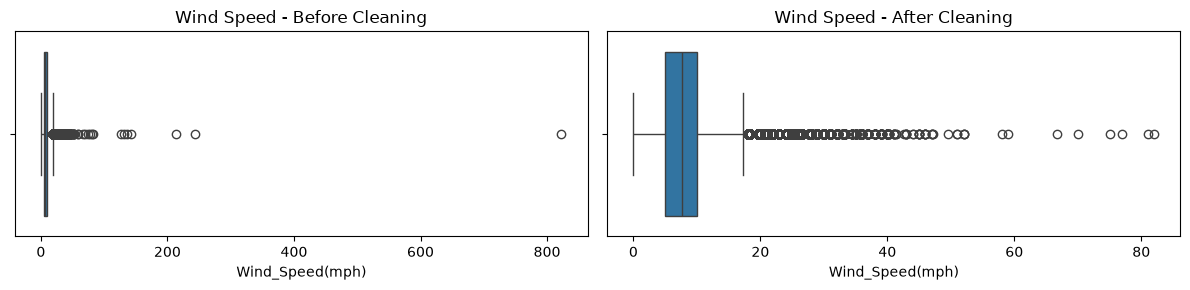

In [19]:
# Box plots showing before and after wind speed changes 

fig, axes = plt.subplots(1, 2, figsize=(12, 3))

sns.boxplot(x=df["Wind_Speed(mph)"], ax=axes[0])
axes[0].set_title("Wind Speed - Before Cleaning")

sns.boxplot(x=dfClean["Wind_Speed(mph)"], ax=axes[1])
axes[1].set_title("Wind Speed - After Cleaning")

plt.tight_layout()
plt.show()

In [20]:
# Calculating the exact numbers presented by the box plot 
wind_speed = dfClean['Wind_Speed(mph)']

Q1 = wind_speed.quantile(0.25)
median = wind_speed.median()
Q3 = wind_speed.quantile(0.75)
IQR = Q3 - Q1
upper_whisker_limit = Q3 + (1.5 * IQR)
wind_speed_outliers = ((wind_speed > (Q3 + (1.5 * IQR))).sum())

print(f"Q1: {Q1}")
print(f"Median: {median:.2f}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Upper Whisker Limit: {upper_whisker_limit}")
print(f"Total Accidents Past Whisker: {wind_speed_outliers}")

Q1: 5.0
Median: 7.68
Q3: 10.0
IQR: 5.0
Upper Whisker Limit: 17.5
Total Accidents Past Whisker: 18918


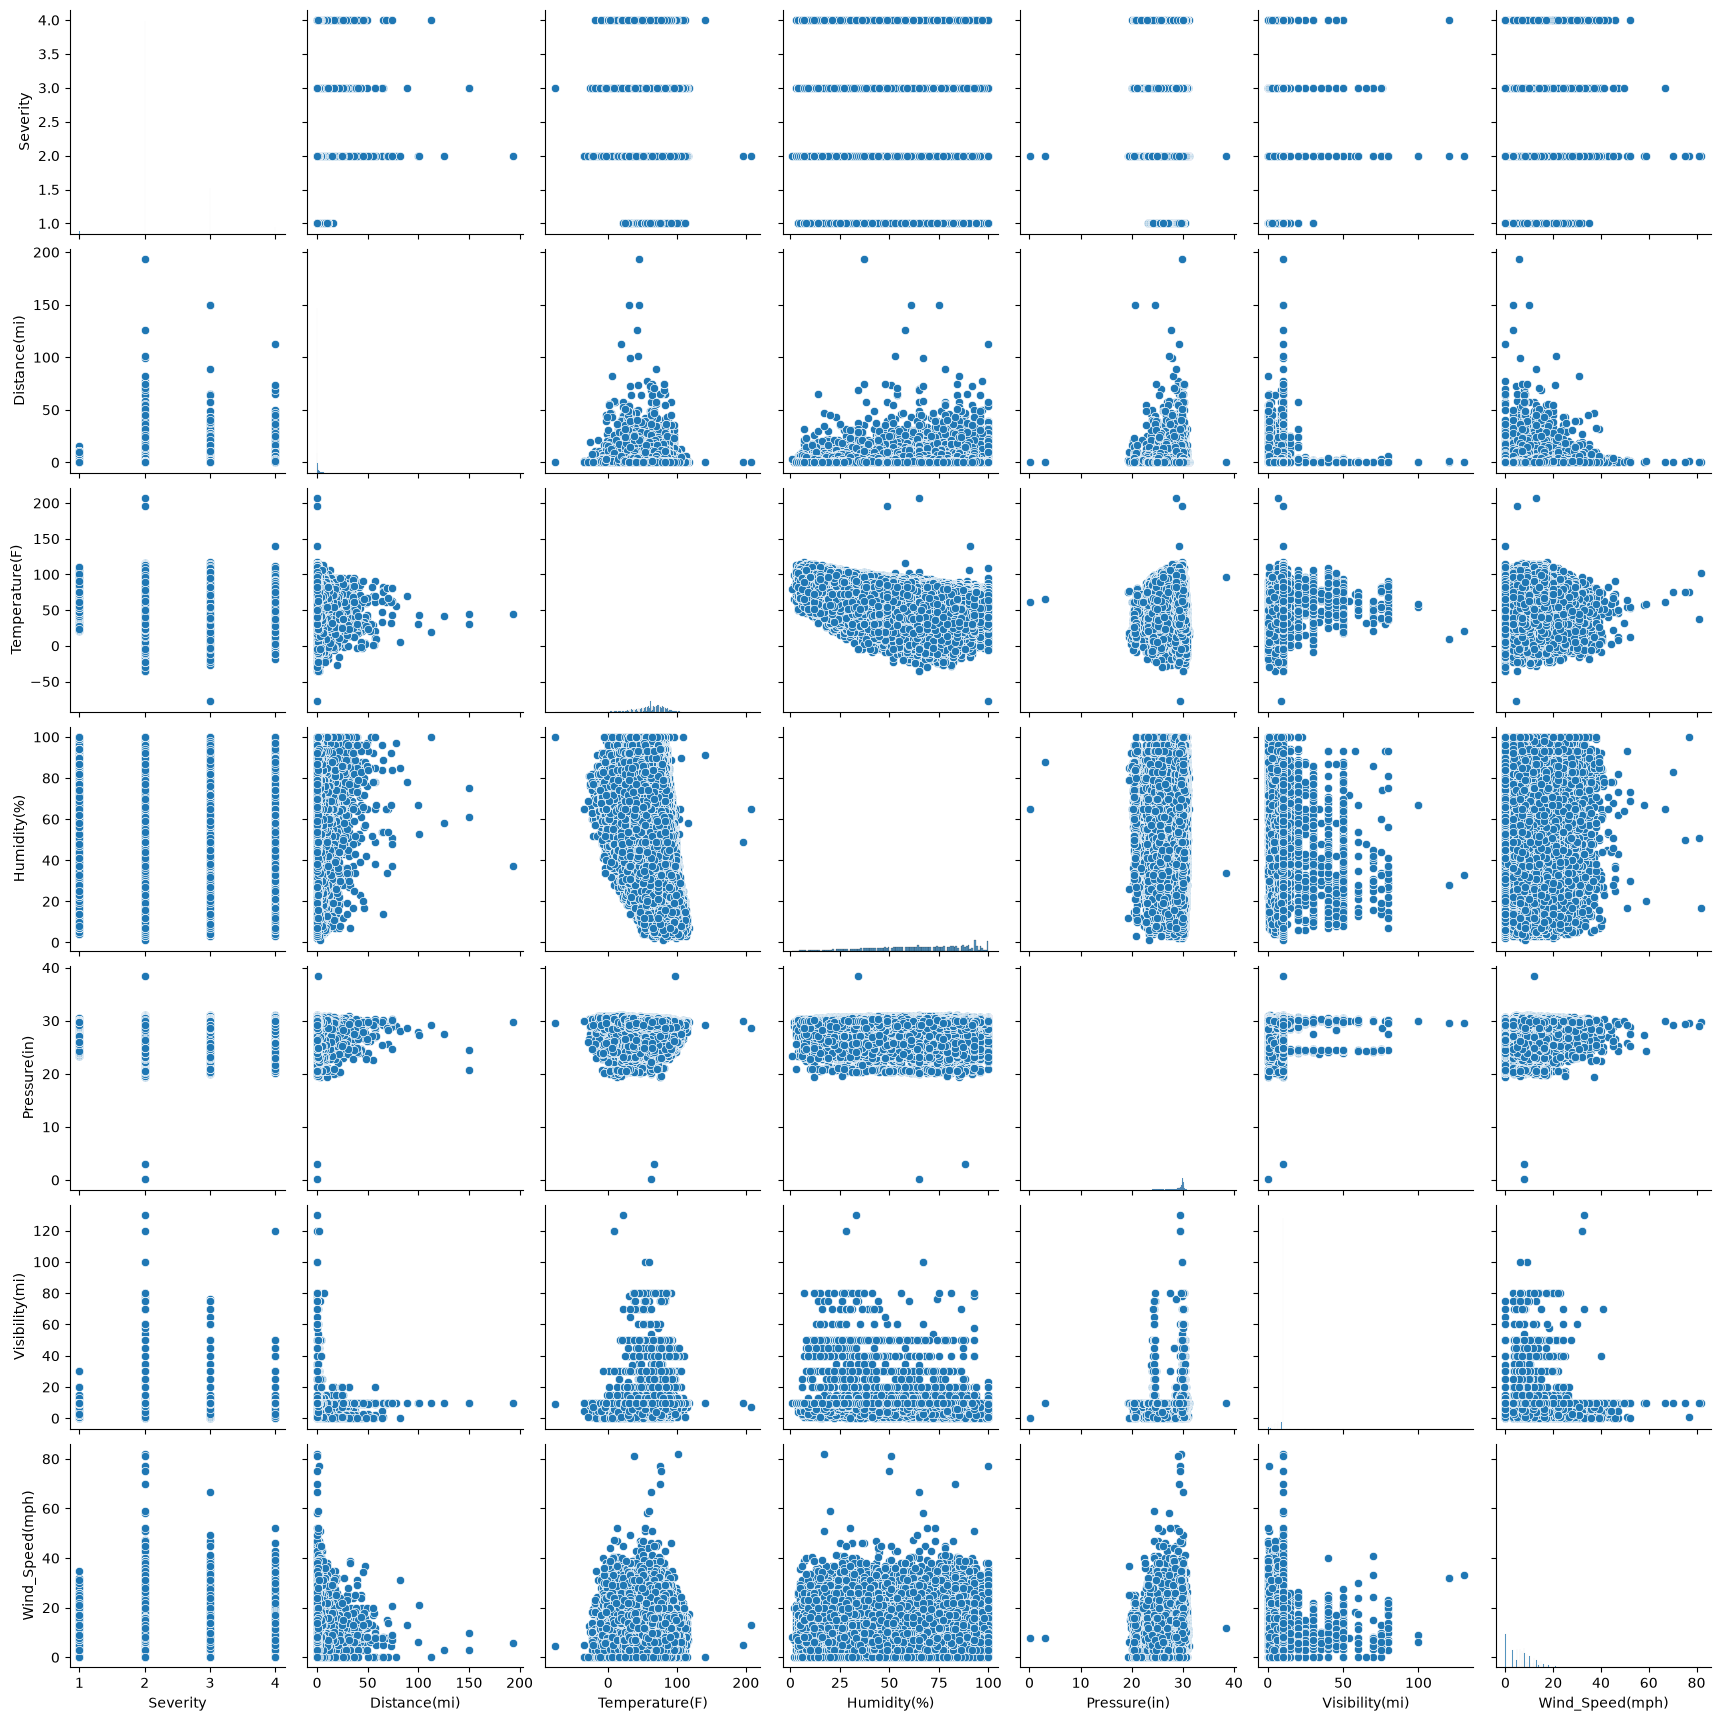

In [21]:
# New pairplot after taking out duplicates, and outliers 
weather_two = dfClean[['Severity','Distance(mi)','Temperature(F)','Humidity(%)','Pressure(in)','Visibility(mi)','Wind_Speed(mph)']].copy()
sns.pairplot(data=weather_two);

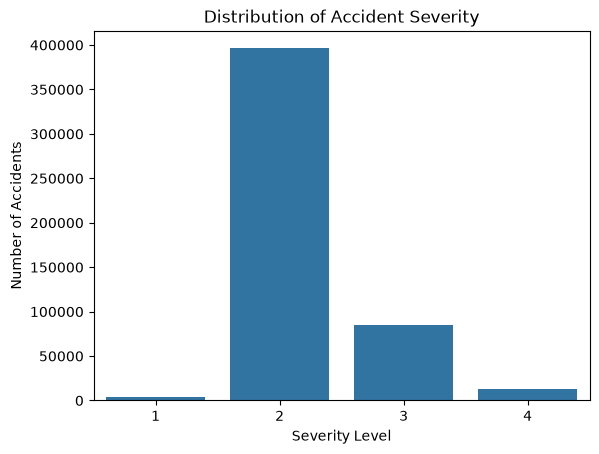

In [22]:
# Simple count plot based on severity of accidents 
sns.countplot(
    data=dfClean,
    x='Severity'
)

plt.title('Distribution of Accident Severity')
plt.xlabel('Severity Level')
plt.ylabel('Number of Accidents')
plt.show()